# LLMs model select

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import mean_absolute_error, cohen_kappa_score, confusion_matrix
from typing import Any

In [18]:
LLM_MODELS = ['gpt_5_mini', 'qwen3_max', 'deepseek_chat', 'gemini_2_5_flash']

In [17]:
LLM_DICT = {'gpt_5_mini':'gpt-5-mini', 'qwen3_max':'qwen3-max', 'deepseek_chat':'deepseek-chat', 'gemini_2_5_flash':'gemini-2.5-flash'}

In [3]:
origindf = pd.read_excel('sample/llms_scored.xlsx')

In [4]:
expertdf = pd.read_excel('expert_label.xlsx')

In [5]:
origindf[expertdf.columns] = expertdf

In [6]:
def normalize_score(value: Any) -> float:
    try:
        score = float(value)
    except Exception:
        score = 0.0
    return float(min(max(score, 0.0), 1.0))
def score_to_label_1_4(score: float) -> int:
    """Map continuous score to the four-level rubric used in the prompt."""
    if pd.isna(score):
        return np.nan
    score = normalize_score(score)
    if score < 0.25:
        return 1
    if score < 0.50:
        return 2
    if score < 0.75:
        return 3
    return 4

In [7]:
def evaluate_model_alignment(
    df: pd.DataFrame,
    model_keys: list[str],
    cross_col: str = "cross_score",
    alpha: float = 0.5,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Return two clean tables:

    1. llm_alignment_df:
       standalone LLM alignment with expert labels.

    2. fused_alignment_df:
       cross-encoder baseline and Cross + LLM fused scores.
    """

    required_cols = {"final_score", "final_label"}
    missing = required_cols - set(df.columns)
    if missing:
        raise ValueError(f"Missing expert label columns: {missing}")

    eval_df = df.copy()

    eval_df["final_score"] = pd.to_numeric(
        eval_df["final_score"],
        errors="coerce",
    )

    eval_df["final_label"] = pd.to_numeric(
        eval_df["final_label"],
        errors="coerce",
    )

    def compute_alignment(
        data: pd.DataFrame,
        score_col: str,
    ) -> dict:
        temp = data.dropna(
            subset=[
                "final_score",
                "final_label",
                score_col,
            ]
        ).copy()

        temp[score_col] = pd.to_numeric(
            temp[score_col],
            errors="coerce",
        )

        temp = temp.dropna(subset=[score_col])

        if len(temp) <= 1:
            return {
                "spearman": np.nan,
                "mae": np.nan,
                "qwk": np.nan,
                "mean": np.nan,
                "std": np.nan,
            }

        pred_labels = temp[score_col].apply(score_to_label_1_4).astype(int)

        return {
            "spearman": spearmanr(
                temp[score_col],
                temp["final_score"],
            ).correlation,
            "mae": mean_absolute_error(
                temp["final_score"],
                temp[score_col],
            ),
            "qwk": cohen_kappa_score(
                temp["final_label"].astype(int),
                pred_labels,
                weights="quadratic",
            ),
            "mean": temp[score_col].mean(),
            "std": temp[score_col].std(),
        }

    # ---------- cross-encoder baseline ----------
    if cross_col not in eval_df.columns:
        raise ValueError(f"Missing cross-encoder column: {cross_col}")

    eval_df[cross_col] = pd.to_numeric(
        eval_df[cross_col],
        errors="coerce",
    )

    cross_metrics = compute_alignment(eval_df, cross_col)

    llm_rows = []
    fused_rows = []

    fused_rows.append({
        "score": "Cross-encoder only",
        "spearman": cross_metrics["spearman"],
        "mae": cross_metrics["mae"],
        "qwk": cross_metrics["qwk"],
        "delta_over_cross_spearman": 0.0,
    })

    # ---------- LLMs ----------
    for model_key in model_keys:
        score_col = f"{model_key}_score"

        if score_col not in eval_df.columns:
            continue

        eval_df[score_col] = pd.to_numeric(
            eval_df[score_col],
            errors="coerce",
        )

        llm_metrics = compute_alignment(eval_df, score_col)

        llm_rows.append({
            "model": model_key,
            "spearman": llm_metrics["spearman"],
            "mae": llm_metrics["mae"],
            "qwk": llm_metrics["qwk"],
            "mean": llm_metrics["mean"],
            "std": llm_metrics["std"],
        })

        fused_temp = eval_df.dropna(
            subset=[
                "final_score",
                "final_label",
                cross_col,
                score_col,
            ]
        ).copy()

        if len(fused_temp) > 1:
            fused_temp["fused_score"] = (
                alpha * fused_temp[cross_col]
                + (1 - alpha) * fused_temp[score_col]
            )

            fused_metrics = compute_alignment(
                fused_temp,
                "fused_score",
            )

            delta_over_cross = (
                fused_metrics["spearman"]
                - cross_metrics["spearman"]
            )

            fused_rows.append({
                "score": f"Cross + {model_key}",
                "spearman": fused_metrics["spearman"],
                "mae": fused_metrics["mae"],
                "qwk": fused_metrics["qwk"],
                "delta_over_cross_spearman": delta_over_cross,
            })

    llm_alignment_df = pd.DataFrame(llm_rows)
    fused_alignment_df = pd.DataFrame(fused_rows)

    return llm_alignment_df, fused_alignment_df

In [19]:
llm_alignment_df, fused_alignment_df = evaluate_model_alignment(
    df=origindf,
    model_keys=LLM_MODELS,
    cross_col="cross_score",
    alpha=0.5,
)

In [20]:
print(llm_alignment_df[['model', 'spearman', 'mae', 'qwk']].to_latex())

\begin{tabular}{llrrr}
\toprule
 & model & spearman & mae & qwk \\
\midrule
0 & gpt_5_mini & 0.767089 & 0.136250 & 0.672234 \\
1 & qwen3_max & 0.755300 & 0.126187 & 0.676226 \\
2 & deepseek_chat & 0.677499 & 0.210375 & 0.516551 \\
3 & gemini_2_5_flash & 0.732649 & 0.171250 & 0.625617 \\
\bottomrule
\end{tabular}



In [21]:
llm_alignment_df.columns

Index(['model', 'spearman', 'mae', 'qwk', 'mean', 'std'], dtype='object')

## KDE

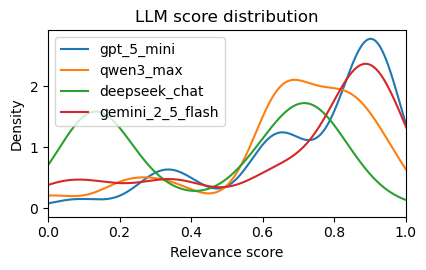

In [22]:
def kde(df):
    plot_df = pd.DataFrame()
    for col in LLM_MODELS:
        plot_df[col] = df[f"{col}_score" ].apply(pd.to_numeric, errors="coerce")

    ax = plot_df.plot(kind="kde", figsize=(4.5, 2.8), xlim=(0, 1))
    ax.set_xlabel("Relevance score")
    ax.set_ylabel("Density")
    ax.set_title("LLM score distribution")
    plt.tight_layout()
    plt.show()
kde(origindf)

# BOX

In [23]:
def boxplot_by_expert_label(df):
    plot_df = pd.DataFrame()

    if "final_label" in df.columns:
        plot_df["expert_label"] = df["final_label"].astype(int)
    else:
        labels = df["final_label"].astype(int)
        plot_df["expert_label"] = labels + 1 if labels.min() == 0 else labels

    for col in LLM_MODELS:
        plot_df[col] = pd.to_numeric(df[f"{col}_score"], errors="coerce")

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(5, 4),
        sharex=True,
        sharey=True,
    )

    axes = axes.ravel()

    for ax, col in zip(axes, LLM_MODELS):
        plot_df.boxplot(
            column=col,
            by="expert_label",
            ax=ax,
            grid=False,
        )

        ax.set_title(LLM_DICT[col])
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_ylim(0, 1)

    # 上面两个图不显示 x 轴刻度标签
    for ax in axes[:2]:
        ax.tick_params(labelbottom=False)

    # 右边两个图不显示 y 轴刻度标签
    for ax in axes[[1, 3]]:
        ax.tick_params(labelleft=False)

    fig.suptitle("")
    fig.supxlabel("Expert label")
    fig.supylabel("LLM relevance score")

    fig.tight_layout()
    plt.show()

    return fig, axes

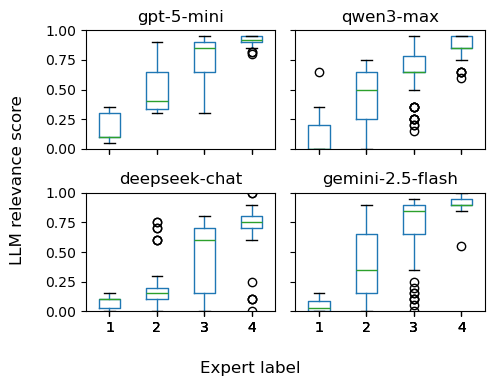

In [24]:
fig, axes = boxplot_by_expert_label(origindf)

In [22]:
def get_expert_label(df):
    if "final_label" in df.columns:
        return pd.to_numeric(df["final_label"], errors="coerce").astype("Int64")

    labels = pd.to_numeric(df["final_label"], errors="coerce").astype("Int64")

    # final_label 如果是 0-3，则转为论文显示的 1-4
    if labels.min() == 0:
        labels = labels + 1

    return labels


def make_confusion_tables(df, model_keys):
    result = {}
    temp = df.copy()
    temp["expert_label"] = get_expert_label(temp)

    labels = [1, 2, 3, 4]

    for model_key in model_keys:
        score_col = f"{model_key}_score"
        pred_col = f"{model_key}_pred_label"

        temp[pred_col] = (
            pd.to_numeric(temp[score_col], errors="coerce")
            .apply(lambda x: score_to_label_1_4(x) if pd.notna(x) else np.nan)
            .astype("Int64")
        )

        valid = temp.dropna(subset=["expert_label", pred_col]).copy()

        table = pd.crosstab(
            valid["expert_label"],
            valid[pred_col],
            rownames=["Expert label"],
            colnames=["Predicted label"],
        ).reindex(index=labels, columns=labels, fill_value=0)

        row_norm = table.div(
            table.sum(axis=1).replace(0, np.nan),
            axis=0,
        )

        result[model_key] = {
            "count": table,
            "row_norm": row_norm,
        }

    return result


def plot_confusion_matrices(
    df,
    model_keys,
    normalize=False,
    figsize=(4.5, 3.8),
):
    temp = df.copy()
    temp["expert_label"] = get_expert_label(temp)

    labels = [1, 2, 3, 4]

    fig, axes = plt.subplots(
        2,
        2,
        figsize=figsize,
        sharex=True,
        sharey=True,
    )

    axes = axes.ravel()

    for ax, model_key in zip(axes, model_keys):
        score_col = f"{model_key}_score"
        pred_col = f"{model_key}_pred_label"

        temp[pred_col] = (
            pd.to_numeric(temp[score_col], errors="coerce")
            .apply(lambda x: score_to_label_1_4(x) if pd.notna(x) else np.nan)
            .astype("Int64")
        )

        valid = temp.dropna(subset=["expert_label", pred_col]).copy()

        cm = confusion_matrix(
            valid["expert_label"].astype(int),
            valid[pred_col].astype(int),
            labels=labels,
        )

        if normalize:
            row_sum = cm.sum(axis=1, keepdims=True)
            plot_cm = np.divide(
                cm,
                row_sum,
                out=np.zeros_like(cm, dtype=float),
                where=row_sum != 0,
            )
        else:
            plot_cm = cm

        im = ax.imshow(plot_cm)

        ax.set_title(model_key)
        ax.set_xticks(range(4))
        ax.set_yticks(range(4))
        ax.set_xticklabels(labels)
        ax.set_yticklabels(labels)

        for i in range(4):
            for j in range(4):
                if normalize:
                    text = f"{plot_cm[i, j]:.2f}"
                else:
                    text = str(cm[i, j])

                ax.text(
                    j,
                    i,
                    text,
                    ha="center",
                    va="center",
                )

    for ax in axes[:2]:
        ax.tick_params(labelbottom=False)

    for ax in axes[[1, 3]]:
        ax.tick_params(labelleft=False)

    fig.supxlabel("Predicted label")
    fig.supylabel("Expert label")

    fig.tight_layout()
    plt.show()

    return fig, axes

In [23]:
conf_tables = make_confusion_tables(origindf, LLM_MODELS)

for model_key, tables in conf_tables.items():
    print("\n", model_key)
    print(tables["count"])


 gpt_5_mini
Predicted label  1   2   3   4
Expert label                  
1                9   5   0   0
2                0  36  18   9
3                0   3  59  95
4                0   0   0  86

 qwen3_max
Predicted label   1   2   3   4
Expert label                   
1                12   1   1   0
2                11  20  28   4
3                 3  10  68  76
4                 0   0   5  81

 deepseek_chat
Predicted label   1   2   3   4
Expert label                   
1                14   0   0   0
2                48   8   5   2
3                56  14  67  20
4                 4   1  23  58

 gemini_2_5_flash
Predicted label   1   2   3    4
Expert label                    
1                14   0   0    0
2                22  18  11   12
3                 8  16  33  100
4                 0   0   1   85


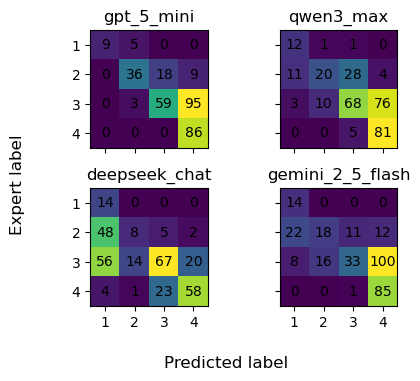

In [24]:
fig, axes = plot_confusion_matrices(
    origindf,
    LLM_MODELS,
    normalize=False,
    figsize=(4.5, 3.8),
)

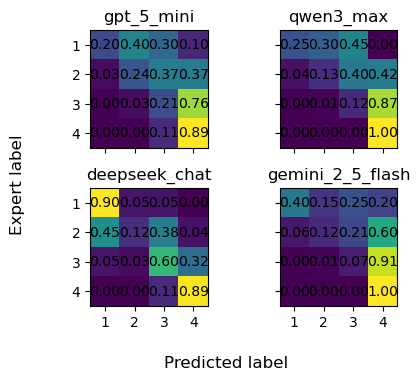

In [43]:
fig, axes = plot_confusion_matrices(
    origindf,
    LLM_MODELS,
    normalize=True,
    figsize=(4.5, 3.8),
)

In [ ]:
def ordinal_error_summary(df, model_keys):
    rows = []
    temp = df.copy()

    if "final_label" in temp.columns:
        temp["expert_label"] = pd.to_numeric(
            temp["final_label"],
            errors="coerce",
        ).astype("Int64")
    else:
        labels = pd.to_numeric(temp["final_label"], errors="coerce").astype("Int64")
        temp["expert_label"] = labels + 1 if labels.min() == 0 else labels

    for model_key in model_keys:
        score_col = f"{model_key}_score"
        pred_col = f"{model_key}_pred_label"

        temp[pred_col] = (
            pd.to_numeric(temp[score_col], errors="coerce")
            .apply(lambda x: score_to_label_1_4(x) if pd.notna(x) else np.nan)
            .astype("Int64")
        )

        valid = temp.dropna(subset=["expert_label", pred_col]).copy()
        error = (valid[pred_col].astype(int) - valid["expert_label"].astype(int)).abs()

        rows.append({
            "model": model_key,
            "mean_ordinal_error": error.mean(),
            "median_ordinal_error": error.median(),
            "exact_match_rate": (error == 0).mean(),
            "within_one_label_rate": (error <= 1).mean(),
            "severe_error_rate": (error >= 2).mean(),
        })

    return pd.DataFrame(rows)


ordinal_error_df = ordinal_error_summary(origindf, LLM_MODELS)
ordinal_error_df.round(3)

,model,mean_ordinal_error,median_ordinal_error,exact_match_rate,within_one_label_rate,severe_error_rate
0,gpt_5_mini,1.009,1.0,0.216,0.803,0.197
1,qwen3_max,0.903,1.0,0.244,0.872,0.128
2,deepseek_chat,0.656,1.0,0.434,0.912,0.088
3,gemini_2_5_flash,1.000,1.0,0.210,0.821,0.179


In [16]:
ordinal_error_df

,model,mean_ordinal_error,median_ordinal_error,exact_match_rate,within_one_label_rate,severe_error_rate
0,gpt_5_mini,1.009375,1.0,0.215625,0.803125,0.196875
1,qwen3_max,0.903125,1.0,0.243750,0.871875,0.128125
2,deepseek_chat,0.656250,1.0,0.434375,0.912500,0.087500
3,gemini_2_5_flash,1.000000,1.0,0.210031,0.821317,0.178683
